In [2]:
print("hello")

hello


In [3]:
pip install yfinance

Note: you may need to restart the kernel to use updated packages.


In [4]:
import yfinance as yf

In [5]:
from datetime import datetime
end=datetime.now()
start=datetime(end.year-20,end.month,end.day)

In [6]:
stock="GOOG"
google_data=yf.download(stock,start,end)

[*********************100%***********************]  1 of 1 completed


In [7]:
google_data

Price,Close,High,Low,Open,Volume
Ticker,GOOG,GOOG,GOOG,GOOG,GOOG
Date,,,,,
2006-10-30,11.758387,11.854365,11.596533,11.715210,263508004
2006-10-31,11.753948,11.896311,11.691031,11.795152,252358369
2006-11-01,11.534605,11.821551,11.479338,11.812423,217865564
2006-11-02,11.594067,11.688316,11.506971,11.534605,210253137
2006-11-03,11.640697,11.688810,11.474402,11.651307,197043811
...,...,...,...,...,...
2026-10-23,317.279999,321.230011,316.989990,317.750000,10856500
2026-10-26,314.190002,318.385010,313.510010,318.045013,16989400


In [8]:
google_data.head()

Price,Close,High,Low,Open,Volume
Ticker,GOOG,GOOG,GOOG,GOOG,GOOG
Date,,,,,
2006-10-30,11.758387,11.854365,11.596533,11.715210,263508004
2006-10-31,11.753948,11.896311,11.691031,11.795152,252358369
2006-11-01,11.534605,11.821551,11.479338,11.812423,217865564
2006-11-02,11.594067,11.688316,11.506971,11.534605,210253137
2006-11-03,11.640697,11.688810,11.474402,11.651307,197043811


In [9]:
google_data.shape

(5031, 5)

In [10]:
google_data.describe()

Price,Close,High,Low,Open,Volume
Ticker,GOOG,GOOG,GOOG,GOOG,GOOG
count,5031.000000,5031.000000,5031.000000,5031.000000,5.031000e+03
mean,72.023348,72.789400,71.220342,71.983118,7.437706e+07
std,79.832926,80.757201,78.850931,79.772916,8.320368e+07
min,6.351804,6.646153,6.101621,6.476896,1.584340e+05
25%,15.133895,15.249856,14.994370,15.122791,2.396500e+07
50%,38.629608,38.775733,38.348380,38.631105,3.697560e+07
75%,104.891502,106.030707,103.756750,104.658708,9.538513e+07
max,398.541260,403.964470,393.177991,396.563718,9.349835e+08


In [11]:
google_data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 5031 entries, 2006-10-30 to 2026-10-29
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, GOOG)   5031 non-null   float64
 1   (High, GOOG)    5031 non-null   float64
 2   (Low, GOOG)     5031 non-null   float64
 3   (Open, GOOG)    5031 non-null   float64
 4   (Volume, GOOG)  5031 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 235.8 KB


In [12]:
google_data.isna().sum()

Price   Ticker
Close   GOOG      0
High    GOOG      0
Low     GOOG      0
Open    GOOG      0
Volume  GOOG      0
dtype: int64

In [13]:
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'clossing price of google data')

<Figure size 1500x500 with 0 Axes>

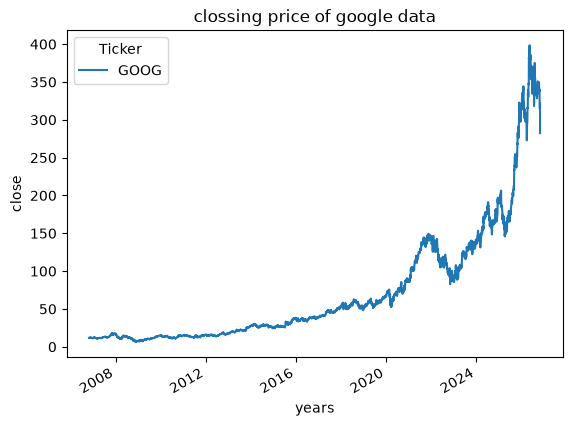

In [14]:
plt.figure(figsize=(15,5))
google_data['Close'].plot()
plt.xlabel("years")
plt.ylabel("close")
plt.title("clossing price of google data")

In [15]:
def plot_graph(figsize,values,column_name):
    plt.figure(figsize=figsize)
    values.plot()
    plt.xlabel("years")
    plt.ylabel(column_name)
    plt.title(f"{column_name} of google data")
    

In [16]:
google_data.columns

MultiIndex([( 'Close', 'GOOG'),
            (  'High', 'GOOG'),
            (   'Low', 'GOOG'),
            (  'Open', 'GOOG'),
            ('Volume', 'GOOG')],
           names=['Price', 'Ticker'])

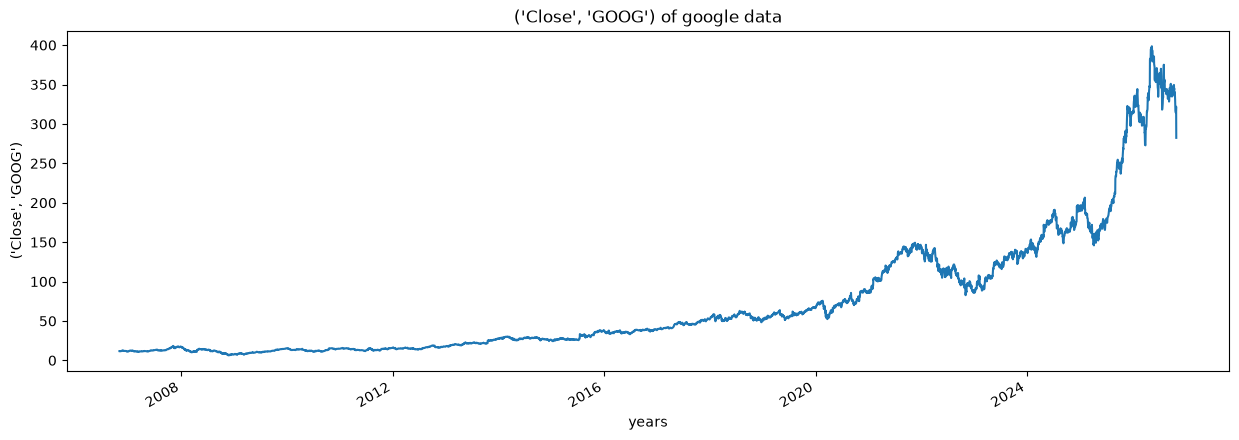

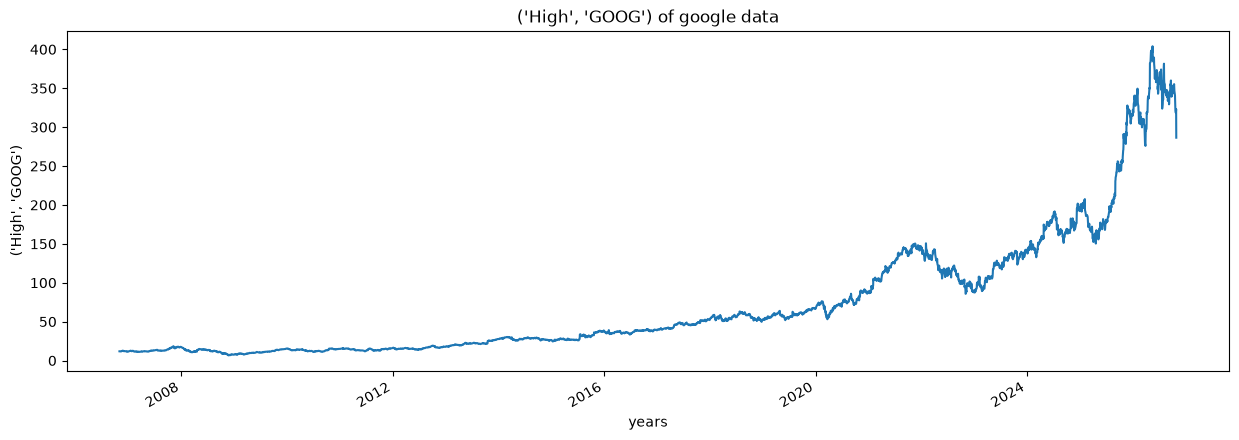

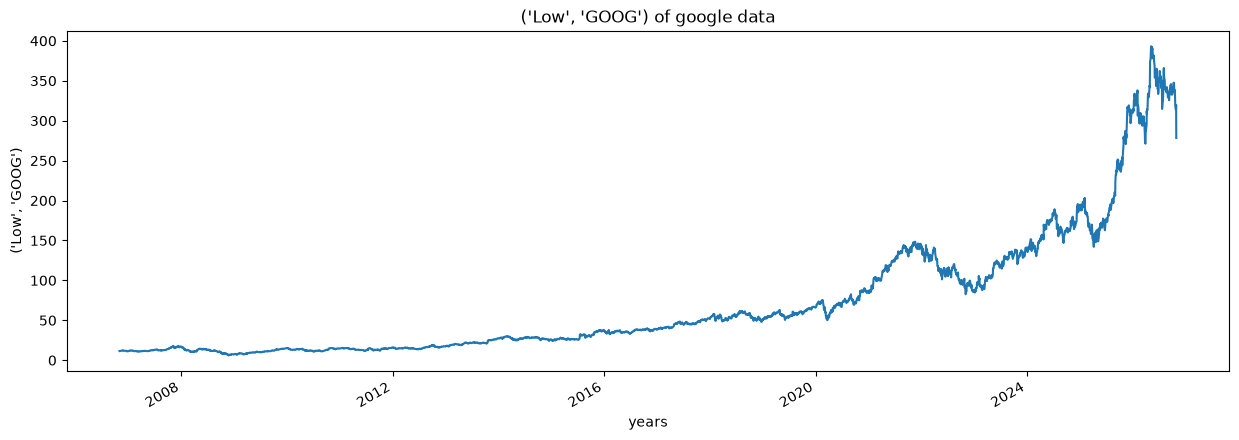

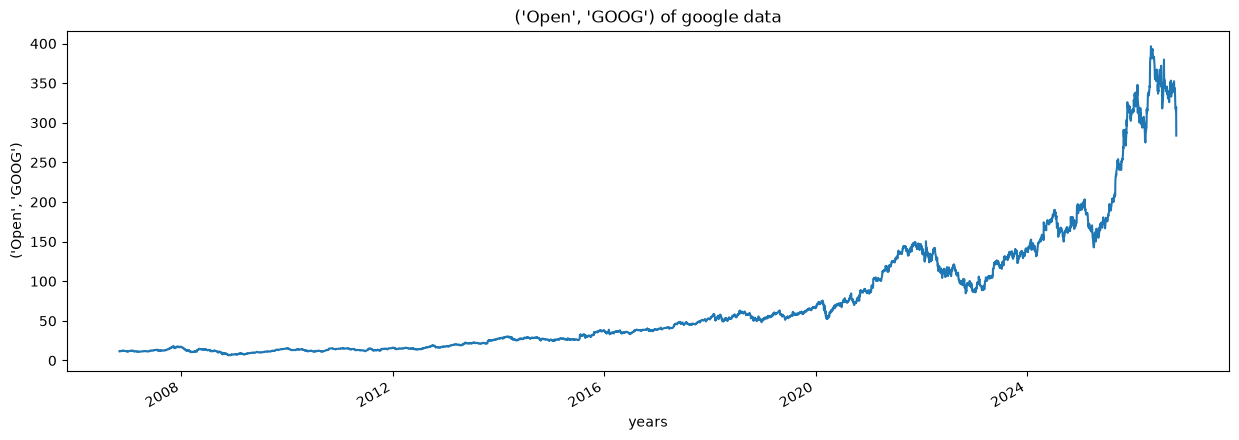

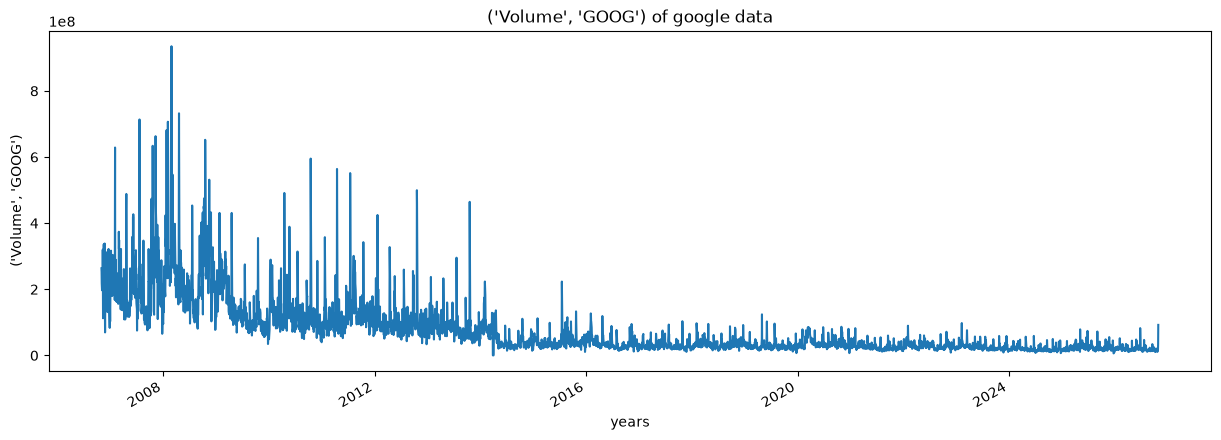

In [17]:
for column in google_data.columns:
    plot_graph((15,5),google_data[column],column)

In [18]:
## 10,20,30,40,50,60,70,80,90,100    ## clculate mooving average
## MA for 5 days == null null null null 30 40 50.....

In [19]:
temp_data=[10,20,30,40,50,60,70,80,90,100]
print(sum(temp_data[:5])/5)
print(sum(temp_data[1:6])/5)

30.0
40.0


In [20]:
import pandas as pd
data=pd.DataFrame([10,20,30,40,50,60,70,80,90,100])
data

,0
0,10
1,20
2,30
3,40
4,50
5,60
6,70
7,80
8,90
9,100


In [21]:
data.rolling(5).mean()

,0
0,NaN
1,NaN
2,NaN
3,NaN
4,30.0
5,40.0
6,50.0
7,60.0
8,70.0
9,80.0


In [22]:
for i in range(2006,2026):
    print(i,list(google_data.index.year).count(i))

2006 43
2007 251
2008 253
2009 252
2010 252
2011 252
2012 250
2013 252
2014 252
2015 252
2016 252
2017 251
2018 251
2019 252
2020 253
2021 252
2022 251
2023 250
2024 252
2025 250


In [23]:
google_data['MA_for_250_days']=google_data['Close'].rolling(250).mean()

In [24]:
google_data['MA_for_250_days'][0:250].tail()

Date
2007-10-22          NaN
2007-10-23          NaN
2007-10-24          NaN
2007-10-25          NaN
2007-10-26    12.401109
Name: MA_for_250_days, dtype: float64

<Figure size 1500x500 with 0 Axes>

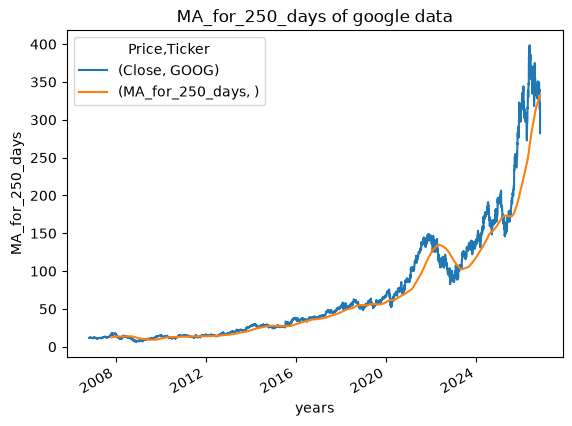

In [25]:
plot_graph((15,5),google_data[['Close','MA_for_250_days']],'MA_for_250_days')

In [26]:
google_data['MA_for_100_days']=google_data['Close'].rolling(100).mean()

In [27]:
google_data['MA_for_100_days'][0:100].tail()

Date
2007-03-20          NaN
2007-03-21          NaN
2007-03-22          NaN
2007-03-23          NaN
2007-03-26    11.702235
Name: MA_for_100_days, dtype: float64

<Figure size 1500x500 with 0 Axes>

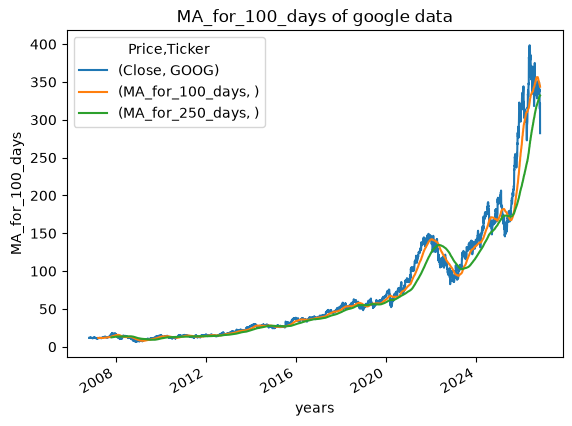

In [28]:
plot_graph((15,5),google_data[['Close','MA_for_100_days','MA_for_250_days']],'MA_for_100_days')

In [29]:
google_data['percentage_change_cp']=google_data['Close'].pct_change()
google_data[['Close','percentage_change_cp']]

Price,Close,percentage_change_cp
Ticker,GOOG,
Date,,
2006-10-30,11.758387,NaN
2006-10-31,11.753948,-0.000377
2006-11-01,11.534605,-0.018661
2006-11-02,11.594067,0.005155
2006-11-03,11.640697,0.004022
...,...,...
2026-10-23,317.279999,-0.010849
2026-10-26,314.190002,-0.009739


In [30]:
google_data['percentage_change_cp']=google_data['Close'].pct_change()
google_data[['Close','percentage_change_cp']].head()

Price,Close,percentage_change_cp
Ticker,GOOG,
Date,,
2006-10-30,11.758387,NaN
2006-10-31,11.753948,-0.000377
2006-11-01,11.534605,-0.018661
2006-11-02,11.594067,0.005155
2006-11-03,11.640697,0.004022


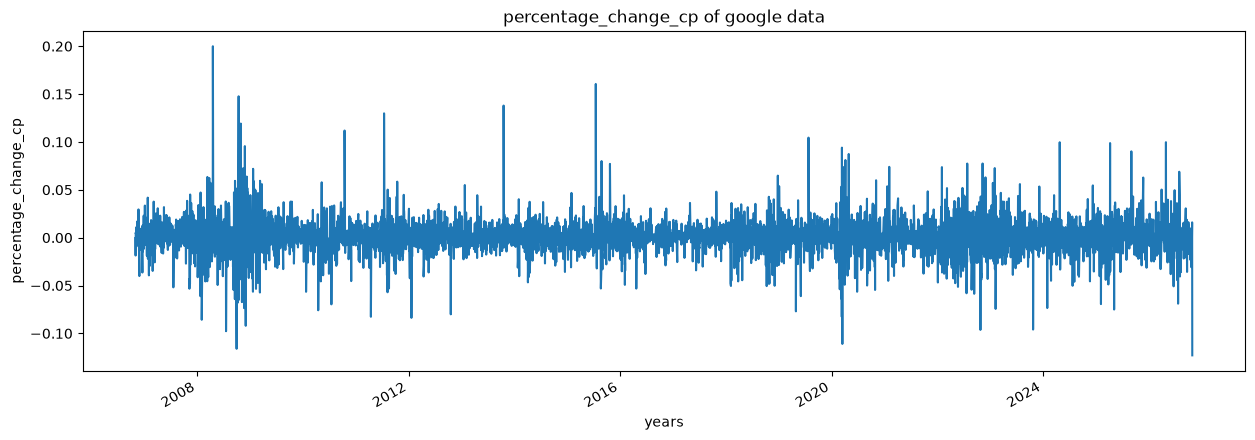

In [31]:
plot_graph((15,5),google_data['percentage_change_cp'],'percentage_change_cp')

In [32]:
close_price=google_data[['Close']]

In [33]:
max(close_price.values),min(close_price.values)

(array([398.54125977]), array([6.35180378]))

In [34]:
## CONVERT THE CLOSE PRICE VALUES BETWEEN 0 AND 1.

from sklearn.preprocessing import MinMaxScaler

scaler=MinMaxScaler(feature_range=(0,1))
scaled_data=scaler.fit_transform(close_price)
scaled_data

array([[0.01378564],
       [0.01377432],
       [0.01321504],
       ...,
       [0.79165357],
       [0.80455557],
       [0.70366044]])

In [35]:
len(scaled_data)

5031

In [36]:
x_data=[]
y_data=[]

for i in range(100,len(scaled_data)):
    x_data.append(scaled_data[i-100:i])
    y_data.append(scaled_data[i])

import numpy as np
x_data,Y_data=np.array(x_data),np.array(y_data)

In [37]:
x_data[0],y_data[0]

(array([[0.01378564],
        [0.01377432],
        [0.01321504],
        [0.01336666],
        [0.01348556],
        [0.01380955],
        [0.013534  ],
        [0.01368687],
        [0.01353778],
        [0.01359566],
        [0.01406622],
        [0.0145865 ],
        [0.01475195],
        [0.01500171],
        [0.01518352],
        [0.01494823],
        [0.01586674],
        [0.01576356],
        [0.0155742 ],
        [0.01430026],
        [0.01459908],
        [0.01429396],
        [0.01430403],
        [0.01405176],
        [0.01430654],
        [0.0144418 ],
        [0.01454938],
        [0.01416751],
        [0.01425999],
        [0.01424867],
        [0.01411341],
        [0.01393789],
        [0.0141348 ],
        [0.0140203 ],
        [0.01291936],
        [0.01328613],
        [0.01292566],
        [0.01250415],
        [0.01246515],
        [0.01258783],
        [0.01324839],
        [0.01290427],
        [0.01277341],
        [0.01322071],
        [0.01420652],
        [0

In [38]:
int(len(x_data)*0.7) ## TRAINING DATA

3451

In [39]:
int(len(y_data))

4931

In [40]:
5030-100-int(len(x_data)*0.7) ## TESTING DATA

1479

In [41]:
splitting_len=int(len(x_data)*0.7)
x_train=x_data[:splitting_len]
y_train=y_data[:splitting_len]

x_test=x_data[splitting_len:]
y_test=y_data[splitting_len:]

In [42]:
print(x_train.shape)  ## display the dimention of the training input

(3451, 100, 1)


In [43]:
y_train=np.array(y_train)
print(y_train.shape)


(3451, 1)


In [44]:
print(x_test.shape)

(1480, 100, 1)


In [45]:
y_test=np.array(y_test)
print(y_test.shape)

(1480, 1)


In [46]:
from keras.models import Sequential
from keras.layers import Dense,LSTM ## Long short term memory
## sequentiel Creates a model where layers are arranged one after another
## Dence create a fully connected nural network
## LSTM learns patterns from sequences
## LSTM can learn patterns from these past prices to help predict a future price.

In [47]:
model=Sequential() ## creates an empty model,add layers to it one by one
model.add(LSTM(128,return_sequences=True,input_shape=(x_train.shape[1],1)))
model.add(LSTM(64,return_sequences=False))
model.add(Dense(25)) ## 25 neurons to process the information
model.add(Dense(1)) ## 1 means the layer has one output neuron

In [48]:
model.compile(optimizer='adam',loss='mean_squared_error')

In [49]:
model.fit(x_train,y_train,batch_size=1,epochs=2)

Epoch 1/2

3451/3451 [==============================] - 144s 40ms/step - loss: 5.8967e-05
Epoch 2/2
3451/3451 [==============================] - 138s 40ms/step - loss: 2.4909e-05


In [50]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 100, 128)          66560     
                                                                 
 lstm_1 (LSTM)               (None, 64)                49408     
                                                                 
 dense (Dense)               (None, 25)                1625      
                                                                 
 dense_1 (Dense)             (None, 1)                 26        
                                                                 
Total params: 117619 (459.45 KB)
Trainable params: 117619 (459.45 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [51]:
prediction=model.predict(x_test)

47/47 [==============================] - 4s 48ms/step


In [52]:
prediction

array([[0.21155886],
       [0.21104059],
       [0.20885366],
       ...,
       [0.806752  ],
       [0.8056792 ],
       [0.81367725]], dtype=float32)

In [53]:
inv_predictions=scaler.inverse_transform(prediction)
inv_predictions

array([[ 89.32296],
       [ 89.1197 ],
       [ 88.26201],
       ...,
       [322.75146],
       [322.3307 ],
       [325.46744]], dtype=float32)

In [54]:
y_test

array([[0.21347471],
       [0.20912772],
       [0.20801635],
       ...,
       [0.79165357],
       [0.80455557],
       [0.70366044]])

In [55]:
inv_y_test=scaler.inverse_transform(y_test)
inv_y_test

array([[ 90.07433319],
       [ 88.36949158],
       [ 87.93362427],
       ...,
       [316.82998657],
       [321.89001465],
       [282.32000732]])

In [56]:
rmse=np.sqrt(np.mean((inv_predictions-inv_y_test)**2))

In [57]:
rmse

4.773632886254142

In [58]:
plotting_data=pd.DataFrame(
    {
        'Original_test_data':inv_y_test.reshape(-1),
         'predictions':inv_predictions.reshape(-1)
    },
    index=google_data.index[splitting_len+100:]
)
plotting_data.head()

,Original_test_data,predictions
Date,,
2020-12-08,90.074333,89.322960
2020-12-09,88.369492,89.119698
2020-12-10,87.933624,88.262009
2020-12-11,88.252602,87.459663
2020-12-14,87.177284,87.199173


<Figure size 1500x600 with 0 Axes>

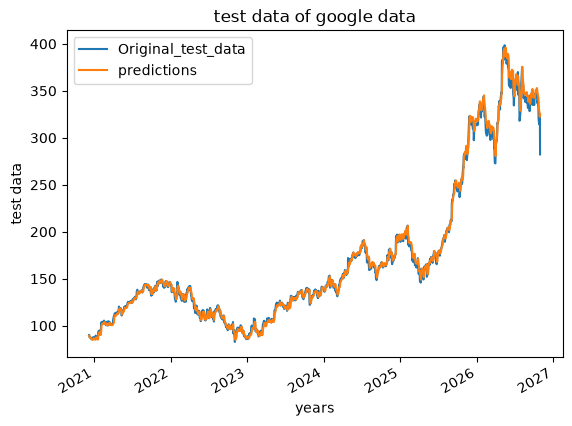

In [59]:
plot_graph((15,6),plotting_data,'test data')

In [60]:
close_price.columns = close_price.columns.get_level_values(0)

<Figure size 1500x600 with 0 Axes>

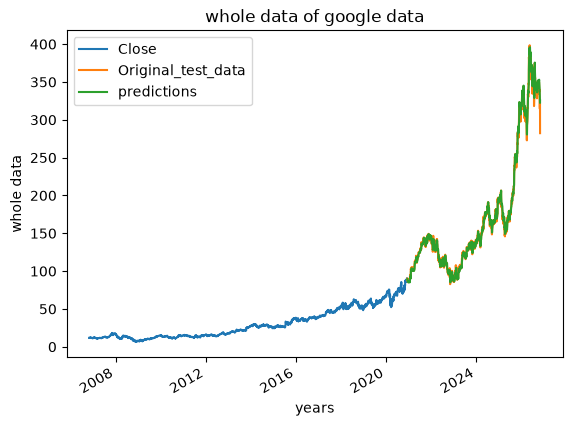

In [61]:
plot_graph((15,6),pd.concat([close_price[:splitting_len+100],plotting_data],axis=0),'whole data')


In [62]:
model.save("Latest_stock_price_model.h5")

c:\Users\saika\Desktop\stock_prediction\venv\Lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(
